<a href="https://colab.research.google.com/github/EdenGebremedhin/DeepShield_Edge_Implementation/blob/main/DeepShield_Edge_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepShield-Edge: Lightweight Deepfake Detection on Edge Devices Using YOLOv8-Nano and ONNX Runtime


- This notebook turns the conclusions of our systematic literature review into a
**working, edge-deployable deepfake detector**.
- The review screened 132 records and synthesised 20 studies, finding the field is dominated by **lightweight CNN
detectors** and **real-time on-device inference**, with **federated learning** the most promising privacy-preserving route.

So we build in two stage:

| Stage | What | Why (from the review) |
|---|---|---|
| 1 | **YOLOv8-nano** face/real-fake classifier (~1.5 M params) | lightweight CNNs are the most common edge approach (7/20) |
| 2 | **ONNX + INT8** edge runtime | real-time / on-device inference (4/20) + compression-aware design |
| 3 | **Benchmark** (latency, FPS, size) | the review asks to *report efficiency alongside accuracy* |

**Dataset:** [`manjilkarki/deepfake-and-real-images`](https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images)
— ~190 k face crops (Real / Fake) derived from the **OpenForensics** deepfake
corpus, already organised as an ImageFolder, so it drops straight into the
YOLO-cls pipeline. *(Alternative: `xhlulu/140k-real-and-fake-faces`.)*


## 1 · Check the runtime

- Confirming that a GPU is attached.
- Training the nano classifier on a free T4 takes only a
few minutes on a sampled subset (configurable below).

In [ ]:
import torch
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected → Runtime > Change runtime type > GPU (T4).")

PyTorch: 2.11.0+cu128 | CUDA available: True
GPU: Tesla T4


## 2 · Install dependencies

- `ultralytics` brings the YOLOv8 family
- `onnx` / `onnxruntime` power the edge runtime.
- `kagglehub` fetches the dataset with no manual download

In [ ]:
%pip -q install "ultralytics>=8.2" onnx onnxruntime kagglehub
import ultralytics; ultralytics.checks()

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 49.4/112.6 GB disk)


## 3 · Configuration

- For a quick first pass keep `SUBSET_PER_CLASS` small (e.g. 6000)
- Set it to `None` to train on the full ~190 k images

In [ ]:
from pathlib import Path

MODEL            = "yolov8n-cls.pt"   # nano = smallest, most edge-friendly
IMG_SIZE         = 224
EPOCHS           = 20
BATCH            = 64
SUBSET_PER_CLASS = None              # None = use the entire dataset
SEED             = 42

DATA_DIR   = Path("cls_data")         # YOLO-cls ImageFolder we build below
ONNX_FP32  = Path("runs/edge/classifier_fp32.onnx")
ONNX_INT8  = Path("runs/edge/classifier_int8.onnx")
for p in (DATA_DIR, ONNX_FP32.parent):
    p.mkdir(parents=True, exist_ok=True)
print("Config ready.")

Config ready.


## 4 · Download the dataset

- `kagglehub` caches the dataset under `~/.cache/kagglehub`.
- We then locate the folder that contains the `Train` / `Validation` splits.

In [ ]:
import kagglehub, os
raw_path = kagglehub.dataset_download("manjilkarki/deepfake-and-real-images")
print("Downloaded to:", raw_path)

def find_root(base):
    # find a directory that contains both a Train* and a Val* subfolder
    for d, subs, _ in os.walk(base):
        names = {s.lower() for s in subs}
        if any(s.startswith("train") for s in names) and \
           any(s.startswith("val") for s in names):
            return d
    return base

ROOT = find_root(raw_path)
print("Dataset root:", ROOT)
print("Splits:", sorted(os.listdir(ROOT)))

Using Colab cache for faster access to the 'deepfake-and-real-images' dataset.
Downloaded to: /kaggle/input/deepfake-and-real-images
Dataset root: /kaggle/input/deepfake-and-real-images/Dataset
Splits: ['Test', 'Train', 'Validation']


## 5 · Build the YOLO-cls ImageFolder

- YOLO classification expects a root with `train/` and `val/` subfolders, each
holding one folder per class.
- We map **Train → train**, **Validation → val**
(and **Test → test**), normalise the class names to lowercase `real` / `fake`,
and optionally **subsample** for speed using fast symlinks (no copying).

In [ ]:
import os, glob, random
random.seed(SEED)

def split_src(root, prefix):
    for name in os.listdir(root):
        if name.lower().startswith(prefix):
            return os.path.join(root, name)
    return None

SRC = {"train": split_src(ROOT, "train"),
       "val":   split_src(ROOT, "val"),
       "test":  split_src(ROOT, "test")}

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def link_split(src, dst_split, per_class):
    if src is None: return
    for cls in os.listdir(src):
        cls_dir = os.path.join(src, cls)
        if not os.path.isdir(cls_dir): continue
        label = "fake" if "fake" in cls.lower() else "real"
        out = DATA_DIR / dst_split / label
        out.mkdir(parents=True, exist_ok=True)
        files = [f for f in glob.glob(os.path.join(cls_dir, "*")) if f.lower().endswith(IMG_EXT)]
        random.shuffle(files)
        if per_class: files = files[:per_class]
        for i, f in enumerate(files):
            link = out / f"{label}_{i:06d}{os.path.splitext(f)[1]}"
            if not link.exists():
                try: os.symlink(os.path.abspath(f), link)
                except FileExistsError: pass

# validation/test get a smaller cap so evaluation stays fast
link_split(SRC["train"], "train", SUBSET_PER_CLASS)
link_split(SRC["val"],   "val",   (SUBSET_PER_CLASS // 4) if SUBSET_PER_CLASS else None)
link_split(SRC["test"],  "test",  (SUBSET_PER_CLASS // 4) if SUBSET_PER_CLASS else None)

for split in ("train", "val", "test"):
    for label in ("real", "fake"):
        d = DATA_DIR / split / label
        n = len(list(d.glob("*"))) if d.exists() else 0
        print(f"{split:5s}/{label:4s}: {n} images")

train/real: 70001 images
train/fake: 70001 images
val  /real: 19787 images
val  /fake: 19641 images
test /real: 5413 images
test /fake: 5492 images


## 6 · Peek at the data

A quick visual sanity check that the real/fake classes look right.

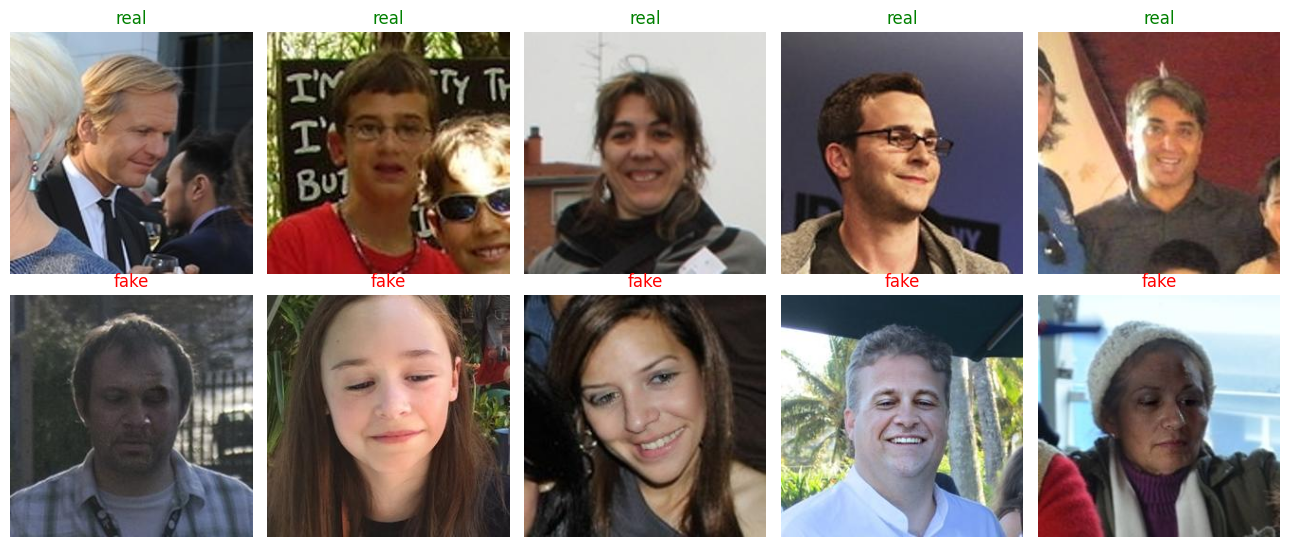

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for row, label in enumerate(("real", "fake")):
    files = list((DATA_DIR / "train" / label).glob("*"))[:5]
    for col, f in enumerate(files):
        axes[row, col].imshow(Image.open(f).convert("RGB"))
        axes[row, col].set_title(label, color=("green" if label=="real" else "red"))
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

## 7 · Train the lightweight classifier

- We fine-tune **`yolov8n-cls`** — the nano variant.
- The review found CNN-based,
lightweight detectors to be the most common edge approach precisely because they balance accuracy against the latency / memory / energy budget of an edge device.
- Light, deployment-friendly augmentation only (horizontal flip, mild rotation).

In [ ]:
from ultralytics import YOLO

model = YOLO(MODEL)
results = model.train(
    data=str(DATA_DIR), epochs=EPOCHS, imgsz=IMG_SIZE, batch=BATCH,
    device=0, project="runs/classify", name="deepshield", exist_ok=True,
    fliplr=0.5, degrees=5.0, hsv_v=0.3, seed=SEED,
)
BEST = Path(results.save_dir) / "weights" / "best.pt"
print("Best weights:", BEST)
print("Classes:", model.names)

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=cls_data, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.3, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=deepshield, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0

- Evaluation on the test set + metrics

Evaluating on 800 test images from cls_data/test

Top-1 accuracy (test): 0.8975

              precision    recall  f1-score   support

        real     0.9077    0.8850    0.8962       400
        fake     0.8878    0.9100    0.8988       400

    accuracy                         0.8975       800
   macro avg     0.8977    0.8975    0.8975       800
weighted avg     0.8977    0.8975    0.8975       800



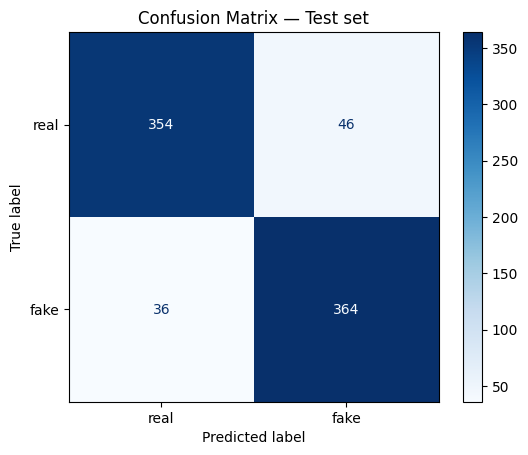

In [ ]:
simport random
from pathlib import Path
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

MAX_TEST_PER_CLASS = 400          # raise for a fuller (slower) evaluation

# use the test split, fall back to val if there isn't one
test_root = DATA_DIR / "test"
if not test_root.exists():
    test_root = DATA_DIR / "val"

samples = []
for label in ("real", "fake"):
    files = sorted((test_root / label).glob("*"))
    random.seed(SEED); random.shuffle(files)
    samples += [(str(f), label) for f in files[:MAX_TEST_PER_CLASS]]
random.shuffle(samples)
paths  = [p for p, _ in samples]
y_true = [l for _, l in samples]
print(f"Evaluating on {len(paths)} test images from {test_root}")

# which class index is "fake"
fake_i = next(k for k, v in model.names.items() if "fake" in v.lower())

# batched inference with the trained model
y_pred, p_fake = [], []
B = 64
for i in range(0, len(paths), B):
    for r in model.predict(paths[i:i+B], imgsz=IMG_SIZE, device=0, verbose=False):
        name = model.names[int(r.probs.top1)]
        y_pred.append("fake" if "fake" in name.lower() else "real")
        p_fake.append(float(r.probs.data[fake_i]))

acc = accuracy_score(y_true, y_pred)
print(f"\nTop-1 accuracy (test): {acc:.4f}\n")
print(classification_report(y_true, y_pred, labels=["real", "fake"], digits=4))

cm = confusion_matrix(y_true, y_pred, labels=["real", "fake"])
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(
    cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test set"); plt.show()

- ROC curve

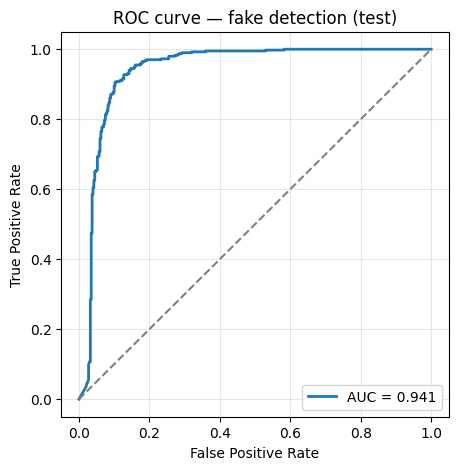

AUC: 0.9407


In [ ]:
from sklearn.metrics import roc_curve, auc
import numpy as np, matplotlib.pyplot as plt

# This plots the ROC curve: how well the model separates real vs fake across
# every threshold, not just 0.5. AUC near 1.0 means strong separation.
y_bin = np.array([1 if t == "fake" else 0 for t in y_true])
fpr, tpr, _ = roc_curve(y_bin, p_fake)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve — fake detection (test)"); plt.legend(loc="lower right")
plt.grid(alpha=0.3); plt.show()
print("AUC:", round(roc_auc, 4))

In [ ]:
# @title
from sklearn.metrics import precision_score, recall_score
print(f"Top-1 accuracy  | Validation | {metrics.top1:.4f}")
print(f"Top-1 accuracy  | Test       | {acc:.4f}")
print(f"Precision (fake)| Test       | {precision_score(y_true, y_pred, pos_label='fake'):.4f}")
print(f"Recall (fake)   | Test       | {recall_score(y_true, y_pred, pos_label='fake'):.4f}")

Top-1 accuracy  | Validation | 0.9689
Top-1 accuracy  | Test       | 0.8975
Precision (fake)| Test       | 0.8878
Recall (fake)   | Test       | 0.9100


- Showing predicted images (correct + misclassified)

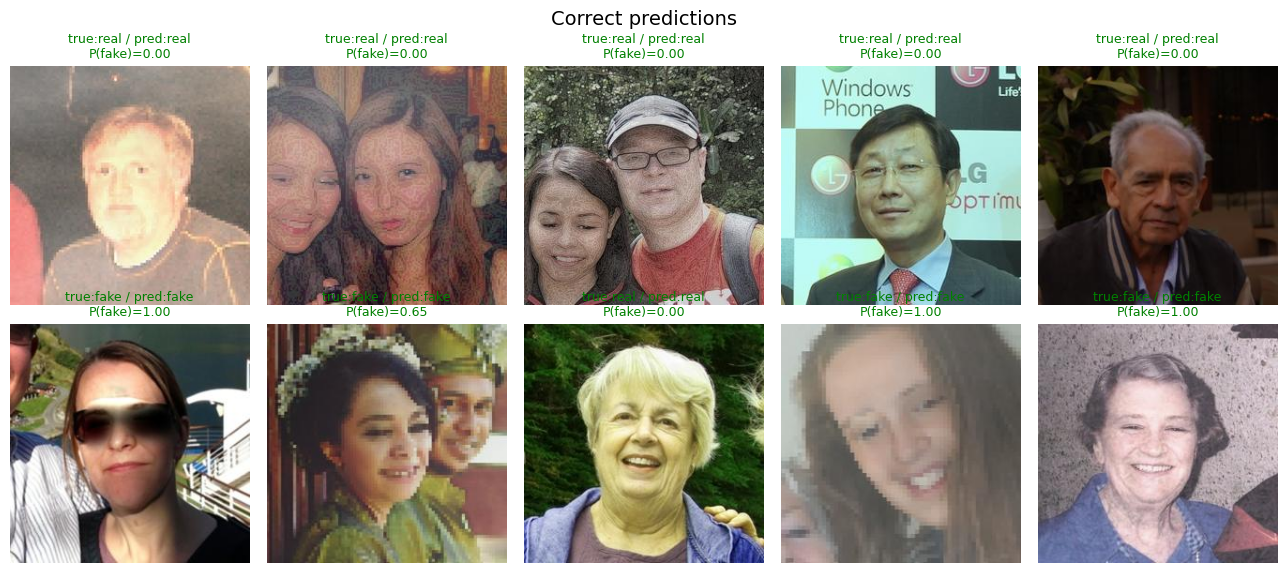

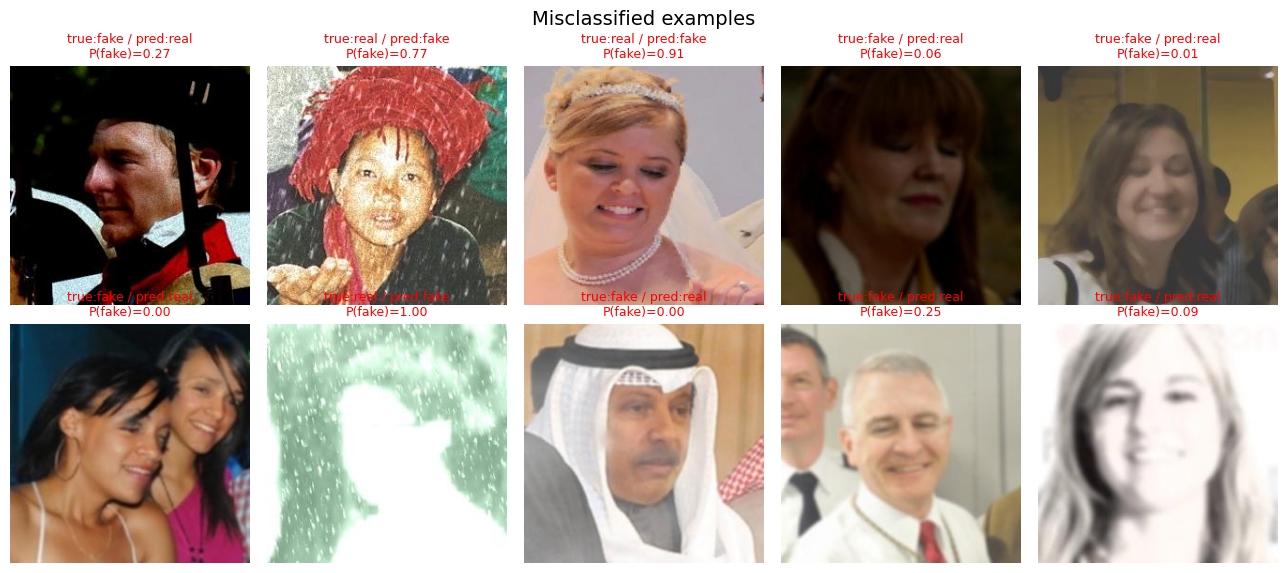


Summary: 718 correct, 82 wrong (89.8% accuracy on shown sample)


In [ ]:
import cv2

def show_grid(items, title, cols=5):
    if not items:
        print(f"{title}: none"); return
    rows = (len(items) + cols - 1) // cols
    plt.figure(figsize=(cols * 2.6, rows * 2.9))
    for i, (path, t, p, pf) in enumerate(items):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        ax = plt.subplot(rows, cols, i + 1); ax.imshow(img); ax.axis("off")
        ax.set_title(f"true:{t} / pred:{p}\nP(fake)={pf:.2f}",
                     color=("green" if t == p else "red"), fontsize=9)
    plt.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

combined  = list(zip(paths, y_true, y_pred, p_fake))
correct   = [c for c in combined if c[1] == c[2]]
incorrect = [c for c in combined if c[1] != c[2]]

show_grid(random.sample(correct, min(10, len(correct))), "Correct predictions")
show_grid(random.sample(incorrect, min(10, len(incorrect))), "Misclassified examples")
print(f"\nSummary: {len(correct)} correct, {len(incorrect)} wrong "
      f"({len(correct)/len(combined):.1%} accuracy on shown sample)")

## 8 · Validate & inspect metrics

- Top-1 accuracy on the validation split, plus the confusion matrix and training
curves that ultralytics writes to the run directory.

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,437,442 parameters, 0 gradients, 3.3 GFLOPs
train: /content/cls_data/train... found 140002 images in 2 classes ✅ 
val: /content/cls_data/val... found 39428 images in 2 classes ✅ 
test: /content/cls_data/test... found 10905 images in 2 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 561.7±300.6 MB/s, size: 10.2 KB)
val: Scanning /content/cls_data/val... 39428 images, 0 corrupt: 100% ━━━━━━━━━━━━ 39428/39428 11.8Git/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2465/2465 20.8it/s 1:59
                   all      0.969          1
Speed: 0.1ms preprocess, 0.5ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val-2
Top-1 accuracy: 0.9689
Top-5 accuracy: 1.0000
confusion_matrix.png


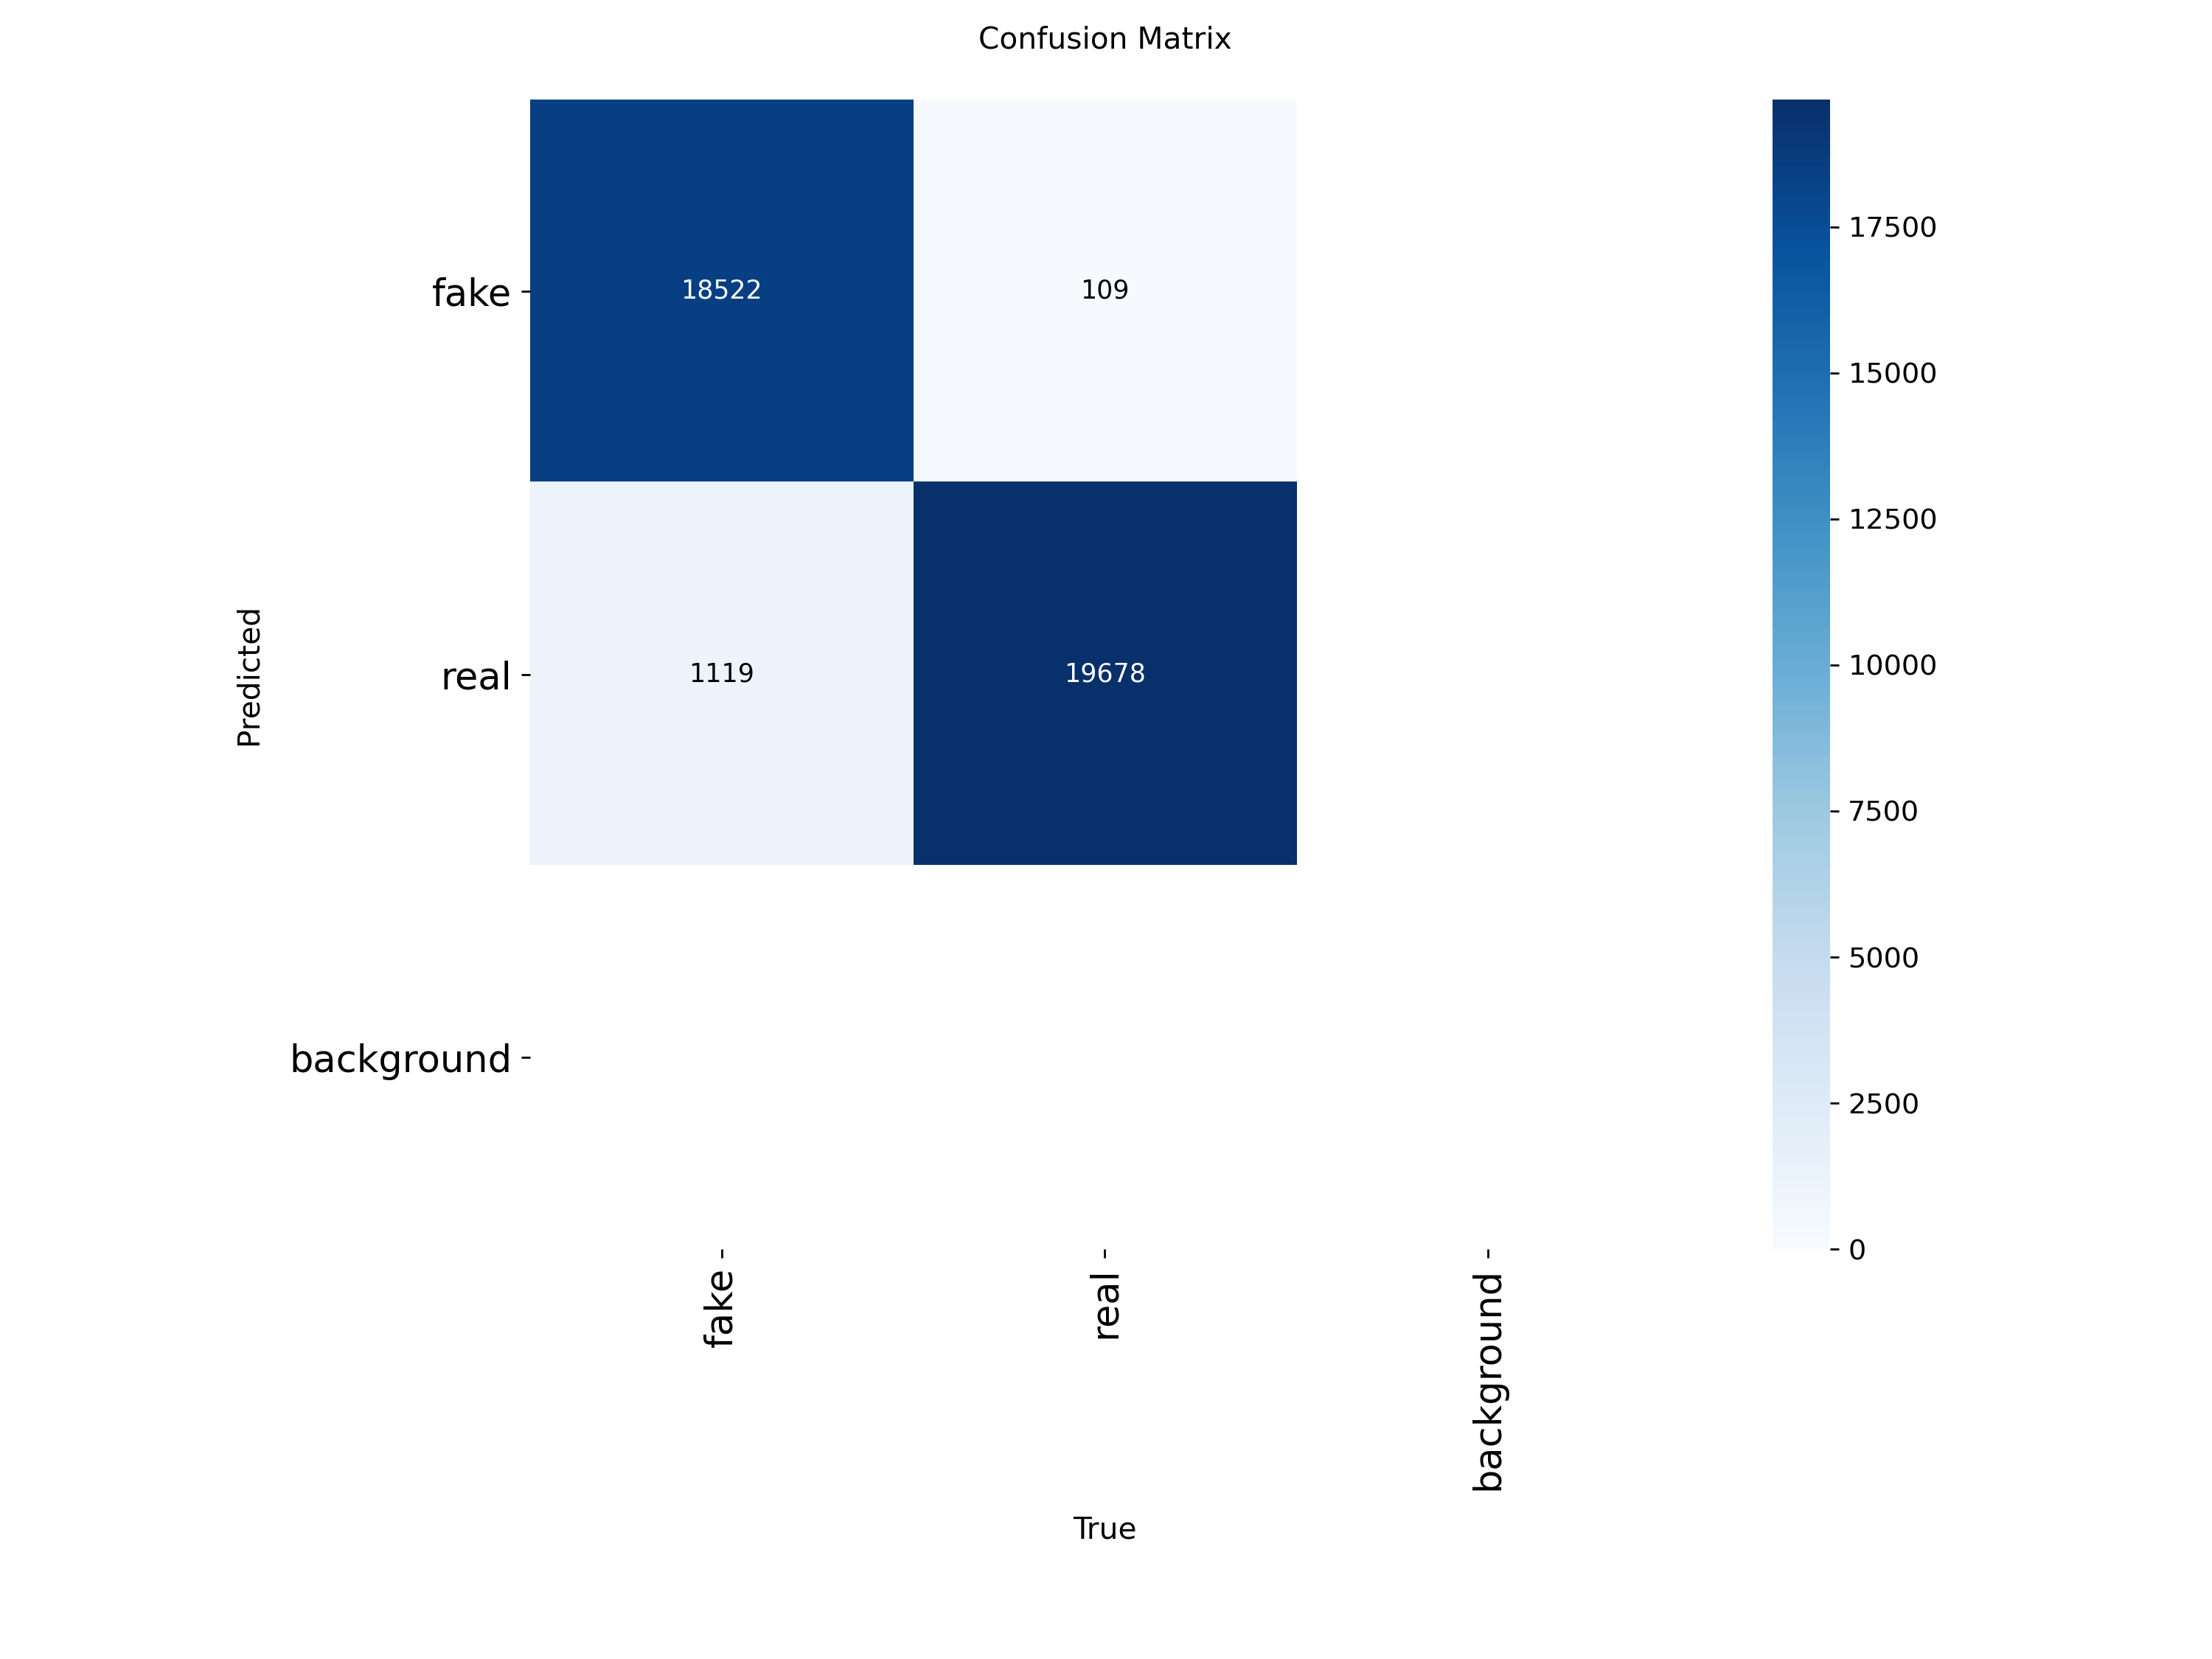

results.png


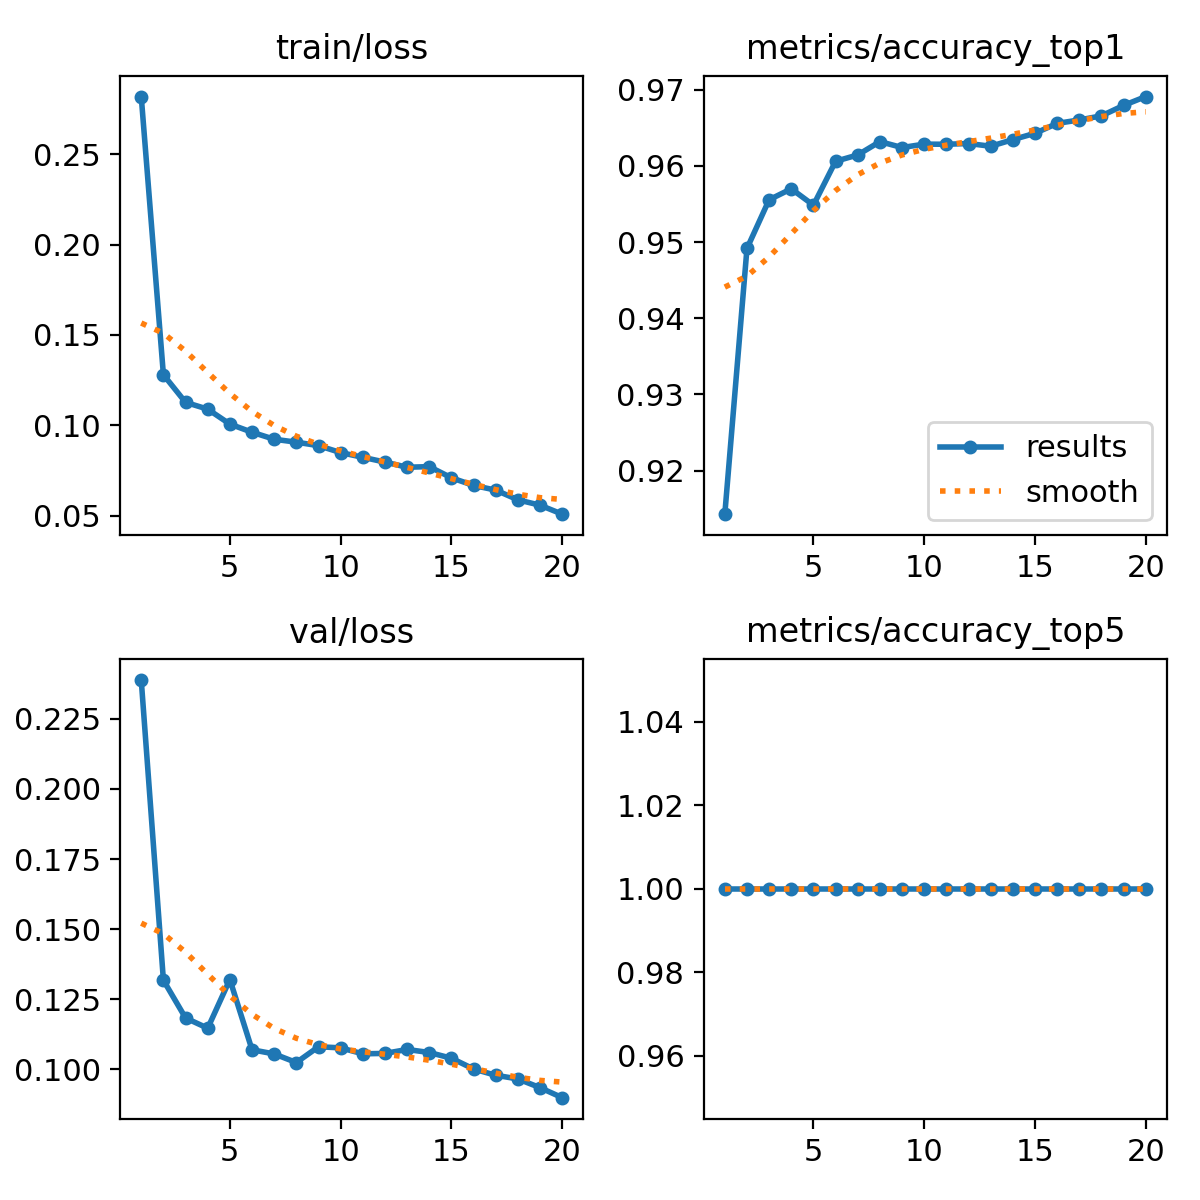

In [ ]:
metrics = model.val(data=str(DATA_DIR), imgsz=IMG_SIZE, device=0, verbose=False)
print(f"Top-1 accuracy: {metrics.top1:.4f}")
print(f"Top-5 accuracy: {metrics.top5:.4f}")

from IPython.display import Image as IPImage, display
run_dir = Path(results.save_dir)
for img in ("confusion_matrix.png", "results.png"):
    p = run_dir / img
    if p.exists():
        print(img); display(IPImage(filename=str(p), width=560))

## 9 · Export to an edge-ready ONNX model (+ INT8)

1. ultralytics exports the `.pt` to ONNX.
2. onnxruntime applies **INT8 dynamic quantisation** — the review's
   *compression-aware design*: ~4× smaller, faster on CPU, no calibration data.
3. We re-attach the class names so the edge runtime needs no side-car file.

In [ ]:
import onnx, shutil
from onnxruntime.quantization import quantize_dynamic, QuantType
from pathlib import Path # Ensure Path is imported if not already

exported = Path(model.export(format="onnx", imgsz=IMG_SIZE, simplify=True, dynamic=False))
shutil.copy(exported, ONNX_FP32)

def set_names(path, names_csv):
    m = onnx.load(str(path))

    # Collect metadata properties excluding 'names'
    filtered_props = [p for p in m.metadata_props if p.key != "names"]

    # Clear existing metadata properties
    # Using del m.metadata_props[:] to clear the RepeatedCompositeContainer
    # This avoids the TypeError encountered with direct assignment.
    del m.metadata_props[:]

    # Add back the filtered properties
    for p in filtered_props:
        new_e = m.metadata_props.add()
        new_e.key = p.key
        new_e.value = p.value

    # Add the new 'names' property
    e = m.metadata_props.add(); e.key = "names"; e.value = names_csv
    onnx.save(m, str(path))

names_csv = ",".join(model.names[i] for i in range(len(model.names)))
set_names(ONNX_FP32, names_csv)
quantize_dynamic(str(ONNX_FP32), str(ONNX_INT8), weight_type=QuantType.QInt8)
set_names(ONNX_INT8, names_csv)

mb = lambda p: Path(p).stat().st_size / 1e6
print(f"FP32 ONNX: {mb(ONNX_FP32):.2f} MB")
print(f"INT8 ONNX: {mb(ONNX_INT8):.2f} MB  ({mb(ONNX_FP32)/mb(ONNX_INT8):.1f}x smaller)")
print("Embedded classes:", names_csv)

## 10 · The edge runtime — ONNX inference (no PyTorch)

- This is the deployable part. It runs on `onnxruntime` alone,  exactly what you ship to a Jetson, a phone, or a Raspberry Pi.
- The same class works for the FP32 or INT8 model.

In [ ]:
import numpy as np, cv2, onnxruntime as ort

class OnnxDeepfakeClassifier:
    def __init__(self, onnx_path, img_size=224):
        so = ort.SessionOptions()
        so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
        self.sess = ort.InferenceSession(str(onnx_path), so, providers=["CPUExecutionProvider"])
        self.inp = self.sess.get_inputs()[0].name
        self.img_size = img_size
        meta = self.sess.get_modelmeta().custom_metadata_map
        raw = meta.get("names", "real,fake")
        if raw.startswith("{"):
            import ast; d = ast.literal_eval(raw); self.names = [d[i] for i in sorted(d)]
        else:
            self.names = [s.strip() for s in raw.split(",")]
        self.fake_idx = next((i for i,n in enumerate(self.names) if n.lower()=="fake"), 0)

    def _pre(self, bgr):
        img = cv2.resize(bgr, (self.img_size, self.img_size))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)/255.0
        return np.ascontiguousarray(np.transpose(img,(2,0,1))[None])

    def predict(self, bgr):
        out = self.sess.run(None, {self.inp: self._pre(bgr)})[0].reshape(-1).astype(np.float32)
        if out.min()<0 or out.max()>1 or abs(out.sum()-1)>1e-2:
            e = np.exp(out-out.max()); out = e/e.sum()
        p_fake = float(out[self.fake_idx])
        return ("fake" if p_fake>=0.5 else "real"), p_fake

edge = OnnxDeepfakeClassifier(ONNX_INT8, IMG_SIZE)
print("Edge runtime loaded. Classes:", edge.names)

# sanity-check on a few held-out test images
import random
samples = []
for label in ("real","fake"):
    fs = list((DATA_DIR/"test"/label).glob("*")) or list((DATA_DIR/"val"/label).glob("*"))
    samples += [(label, f) for f in random.sample(fs, min(3,len(fs)))]
correct = 0
for true, f in samples:
    pred, p = edge.predict(cv2.imread(str(f)))
    correct += (pred==true)
    print(f"true={true:4s}  pred={pred:4s}  P(fake)={p:.3f}  {Path(f).name}")
print(f"\nquick check: {correct}/{len(samples)} correct")

Edge runtime loaded. Classes: ['fake', 'real']
true=real  pred=real  P(fake)=0.000  real_002656.jpg
true=real  pred=real  P(fake)=0.000  real_001783.jpg
true=real  pred=real  P(fake)=0.000  real_002531.jpg
true=fake  pred=fake  P(fake)=1.000  fake_001551.jpg
true=fake  pred=fake  P(fake)=0.968  fake_004213.jpg
true=fake  pred=fake  P(fake)=1.000  fake_004792.jpg

quick check: 6/6 correct


- Comparing the deployed INT8 model to the trained one - it reuses the edge ONNX classifier.
- It gives the FP32-vs-INT8 accuracy line for your results table:

In [ ]:
edge_pred = [edge.predict(cv2.imread(p))[0] for p in paths]
print(f"FP32 trained model : {acc:.4f}")
print(f"INT8 edge model    : {accuracy_score(y_true, edge_pred):.4f}")

FP32 trained model : 0.8975
INT8 edge model    : 0.9050


## 11 · Benchmark edge efficiency

- Latency (mean / p50 / p90 / p95), throughput, and on-disk size, its the efficiency numbers.

In [ ]:
import time, numpy as np

def benchmark(onnx_path, runs=200, warmup=20, img_size=224):
    clf = OnnxDeepfakeClassifier(onnx_path, img_size)
    sample = np.random.randint(0,255,(img_size,img_size,3),dtype=np.uint8)
    for _ in range(warmup): clf.predict(sample)
    ts = np.empty(runs)
    for i in range(runs):
        t0=time.perf_counter(); clf.predict(sample); ts[i]=(time.perf_counter()-t0)*1000
    return {
        "model": str(onnx_path),
        "size_MB": round(Path(onnx_path).stat().st_size/1e6,3),
        "latency_ms": {"mean":round(ts.mean(),3),"p50":round(np.percentile(ts,50),3),
                       "p90":round(np.percentile(ts,90),3),"p95":round(np.percentile(ts,95),3)},
        "throughput_fps": round(1000/ts.mean(),1),
    }

import json
for m in (ONNX_FP32, ONNX_INT8):
    print(json.dumps(benchmark(m), indent=2))

{
  "model": "runs/edge/classifier_fp32.onnx",
  "size_MB": 5.779,
  "latency_ms": {
    "mean": 5.196,
    "p50": 5.091,
    "p90": 5.765,
    "p95": 6.315
  },
  "throughput_fps": 192.4
}
{
  "model": "runs/edge/classifier_int8.onnx",
  "size_MB": 1.514,
  "latency_ms": {
    "mean": 43.105,
    "p50": 37.648,
    "p90": 67.521,
    "p95": 70.289
  },
  "throughput_fps": 23.2
}


- FP32 vs INT8 bar chart

In [ ]:
print(f"{'Model':24s} | {'Size(MB)':>9} | {'Mean lat(ms)':>12} | {'FPS':>7}")
for name, p in [("YOLOv8n-cls FP32 (ONNX)", ONNX_FP32),
                ("YOLOv8n-cls INT8 (ONNX)", ONNX_INT8)]:
    r = benchmark(p)
    print(f"{name:24s} | {r['size_MB']:>9} | {r['latency_ms']['mean']:>12} | {r['throughput_fps']:>7}")

Model                    |  Size(MB) | Mean lat(ms) |     FPS
YOLOv8n-cls FP32 (ONNX)  |     5.779 |       11.284 |    88.6
YOLOv8n-cls INT8 (ONNX)  |     1.514 |        44.38 |    22.5


In [ ]:
## 12 · Try it on your own image

# - Upload any photo
# - We detect faces with OpenCV (zero-download), classify each one,
# and draw the verdict.

# @title
from google.colab import files
import cv2, numpy as np
from IPython.display import Image as IPImage, display

up = files.upload()
cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

for name in up:
    img = cv2.imdecode(np.frombuffer(up[name], np.uint8), cv2.IMREAD_COLOR)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = cascade.detectMultiScale(gray, 1.1, 5, minSize=(48,48))
    if len(faces)==0:
        faces = [(0,0,img.shape[1],img.shape[0])]   # fall back to whole image
    for (x,y,w,h) in faces:
        pad = int(0.15*w)
        crop = img[max(0,y-pad):y+h+pad, max(0,x-pad):x+w+pad]
        label, p = edge.predict(crop)
        col = (60,60,220) if label=="fake" else (80,175,76)
        cv2.rectangle(img,(x,y),(x+w,y+h),col,2)
        cv2.putText(img,f"{label} {p:.2f}",(x,max(20,y-8)),
                    cv2.FONT_HERSHEY_SIMPLEX,0.7,col,2,cv2.LINE_AA)
    out = "pred_" + name
    cv2.imwrite(out, img); display(IPImage(filename=out, width=480))

## 12 · Federated learning (Optional)

The review concludes federated learning is the **most promising** route to
privacy-preserving, deployable detection (S021, I004, I008, S062): each site
trains on its own faces and shares only model weights, never the media.


```python
# %pip install "flwr>=1.8"
# from deepshield.federated.client import build_client   # after unzipping the repo
# import flwr as fl
# fl.simulation.start_simulation(client_fn=..., num_clients=3, ...)
```

## 13 · How this maps to the review

- **RQ1 — architectures:** lightweight CNN (YOLOv8-nano), extensible to ViT / hybrid backbones.
- **RQ2 — edge techniques:** lightweight design **+** real-time on-device inference **+** INT8 compression
- **RQ3 — modality / datasets:** image faces from the OpenForensics-derived deepfake set, extends to video by classifying sampled frames.
- **RQ4 — the gap:** efficiency is reported as a first-class metric *vision-language reasoning at the edge* remains the documented next step (distil a multimodal teacher into this nano head).

**Takeaway.** A nano YOLO classifier + INT8 ONNX runtime delivers a small, fast,
privacy-friendly deepfake detector that directly embodies the review's findings
and leaves a clean hook for the multimodal at the edge frontier it identifies.